In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
df = pd.read_csv(
    r'C:\Users\ibrahim khan\Desktop\Sentiments_Analyzer\amazon_cells_labelled.txt',
    sep='\t',
    header=None,
    names=['Review', 'Sentiment']
)

df.head()

,Review,Sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [6]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

# Display first 5 reviews
df.head()

Dataset Shape: (1000, 2)

Column Names:
Index(['Review', 'Sentiment'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Review     1000 non-null   object
 1   Sentiment  1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


,Review,Sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [8]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
Review       0
Sentiment    0
dtype: int64

Duplicate Rows:
10


In [10]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check the updated dataset
print("Updated Dataset Shape:", df.shape)

# Check duplicates again
print("Remaining Duplicates:", df.duplicated().sum())

Updated Dataset Shape: (990, 2)
Remaining Duplicates: 0


Sentiment Distribution:
Sentiment
0    497
1    493
Name: count, dtype: int64


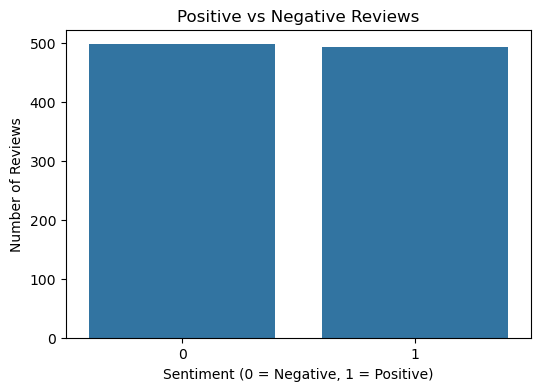

In [14]:
# Count positive and negative reviews
sentiment_counts = df['Sentiment'].value_counts()

print("Sentiment Distribution:")
print(sentiment_counts)

# Visualize the distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Sentiment')

plt.title('Positive vs Negative Reviews')
plt.xlabel('Sentiment (0 = Negative, 1 = Positive)')
plt.ylabel('Number of Reviews')

plt.show()

In [16]:
import re

# Function to clean text
def clean_text(text):
    text = text.lower()                  # Convert to lowercase
    text = re.sub(r'[^\w\s]', '', text)  # Remove punctuation
    text = re.sub(r'\s+', ' ', text)     # Remove extra spaces
    return text.strip()

# Apply cleaning to all reviews
df['Clean_Review'] = df['Review'].apply(clean_text)

# Display original and cleaned reviews
df[['Review', 'Clean_Review']].head(10)

,Review,Clean_Review
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


In [18]:
# Create a tokenizer
tokenizer = Tokenizer()

# Learn the vocabulary from our reviews
tokenizer.fit_on_texts(df['Clean_Review'])

# Convert reviews into sequences of numbers
sequences = tokenizer.texts_to_sequences(df['Clean_Review'])

# Display examples
print("Original Review:")
print(df['Clean_Review'].iloc[0])

print("\nTokenized Review:")
print(sequences[0])

# Total unique words
print("\nTotal Unique Words:", len(tokenizer.word_index))

Original Review:
so there is no way for me to plug it in here in the us unless i go by a converter

Tokenized Review:
[34, 113, 5, 58, 206, 12, 51, 8, 149, 4, 19, 326, 19, 1, 532, 533, 2, 230, 181, 6, 785]

Total Unique Words: 1900


In [20]:
# Apply padding to make all sequences equal in length
max_length = max(len(seq) for seq in sequences)

padded_sequences = pad_sequences(
    sequences,
    maxlen=max_length,
    padding='post'
)

# Display results
print("Maximum Sequence Length:", max_length)

print("\nOriginal Sequence:")
print(sequences[0])

print("\nPadded Sequence:")
print(padded_sequences[0])

print("\nPadded Dataset Shape:")
print(padded_sequences.shape)

Maximum Sequence Length: 30

Original Sequence:
[34, 113, 5, 58, 206, 12, 51, 8, 149, 4, 19, 326, 19, 1, 532, 533, 2, 230, 181, 6, 785]

Padded Sequence:
[ 34 113   5  58 206  12  51   8 149   4  19 326  19   1 532 533   2 230
 181   6 785   0   0   0   0   0   0   0   0   0]

Padded Dataset Shape:
(990, 30)


In [24]:
# Separate input features and target labels
X = padded_sequences
y = df['Sentiment'].values

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check dataset sizes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Labels Shape:", y_train.shape)
print("Testing Labels Shape:", y_test.shape)

Training Data Shape: (792, 30)
Testing Data Shape: (198, 30)

Training Labels Shape: (792,)
Testing Labels Shape: (198,)


In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dense

model = Sequential([
    Input(shape=(30,)),
    Embedding(input_dim=1901, output_dim=64),
    SimpleRNN(64),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 30, 64)         │       121,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 129,985 (507.75 KB)

 Trainable params: 129,985 (507.75 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [30]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.7736 - val_loss: 0.7330
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.7736 - val_loss: 0.7404
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 0.7736 - val_loss: 0.7495
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.7736 - val_loss: 0.7549
Epoch 5/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 0.7736 - val_loss: 0.7679
Epoch 6/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 1.0000 - loss: 9.1251e-04 - val_accuracy: 0.7799 - val_loss: 0.7723
Epoch 7/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 1.0000 - loss: 8.2217e-04 - val_accuracy: 0.7799 - val_loss: 0.7826
Epoch 8/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 1.0000 - loss: 7.4858e-04 - val_accuracy

In [32]:
# Evaluate model on testing data
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7121 - loss: 1.1646

Test Loss: 1.1645632982254028
Test Accuracy: 71.21211886405945 %


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Confusion Matrix:
[[67 32]
 [25 74]]

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.68      0.70        99
    Positive       0.70      0.75      0.72        99

    accuracy                           0.71       198
   macro avg       0.71      0.71      0.71       198
weighted avg       0.71      0.71      0.71       198



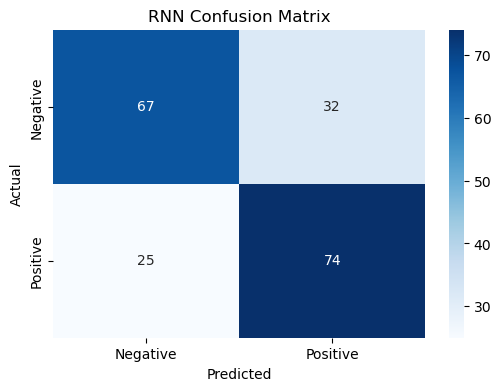

In [34]:
from sklearn.metrics import confusion_matrix, classification_report

# Generate predictions
y_pred_prob = model.predict(X_test)

# Convert probabilities into binary predictions
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

# Visualize Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('RNN Confusion Matrix')
plt.show()

In [35]:
def predict_sentiment(review):

    # Clean the review
    cleaned = clean_text(review)

    # Convert text into numerical sequence
    sequence = tokenizer.texts_to_sequences([cleaned])

    # Apply padding
    padded = pad_sequences(
        sequence,
        maxlen=30,
        padding='post'
    )

    # Predict sentiment
    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: Positive")
    else:
        print("Sentiment: Negative")

    print("Confidence:", round(float(prediction) * 100, 2), "%")


# Test examples
predict_sentiment("This product is amazing and I love it!")

predict_sentiment("This product is terrible and a waste of money.")

Sentiment: Positive
Confidence: 99.75 %
Sentiment: Negative
Confidence: 15.82 %
